In [10]:
import sys
from pathlib import Path

# Add project root so `import shared` works
root = Path.cwd().resolve()
while root != root.parent and not (root / "shared").exists():
    root = root.parent
if not (root / "shared").exists():
    raise RuntimeError("Could not find project root containing 'shared/'")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from shared.paths import get_experiment_paths
from shared.visualization import show_grid, save_grid

import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [11]:
def latest_ckpt(models_dir):
    ckpts = sorted(models_dir.glob("ckpt_epoch_*.pth"))
    if not ckpts:
        raise FileNotFoundError(f"No ckpt_epoch_*.pth found in {models_dir}")
    return ckpts[-1]

In [12]:
import torch.nn as nn
import torch

class CGenerator(nn.Module):
    def __init__(self, z_dim=100, num_classes=10, embed_dim=100, img_channels=1, feat=64):
        super().__init__()
        self.embed = nn.Embedding(num_classes, embed_dim)
        in_ch = z_dim + embed_dim

        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_ch, feat*4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(feat*4),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*4, feat*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat*2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*2, feat, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat),
            nn.ReLU(True),

            nn.Conv2d(feat, img_channels, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, z, y):
        y_emb = self.embed(y).unsqueeze(2).unsqueeze(3)  # (N, embed_dim, 1, 1)
        x = torch.cat([z, y_emb], dim=1)
        return self.net(x)

class CDiscriminator(nn.Module):
    def __init__(self, num_classes=10, img_channels=1, feat=64):
        super().__init__()
        self.embed = nn.Embedding(num_classes, 28*28)
        in_ch = img_channels + 1

        self.net = nn.Sequential(
            nn.Conv2d(in_ch, feat, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feat, feat*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat*2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feat*2, feat*4, 3, 2, 1, bias=False),
            nn.BatchNorm2d(feat*4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feat*4, 1, 4, 1, 0),
        )

    def forward(self, x, y):
        y_map = self.embed(y).view(-1, 1, 28, 28)
        inp = torch.cat([x, y_map], dim=1)
        out = self.net(inp)
        return out.view(-1)

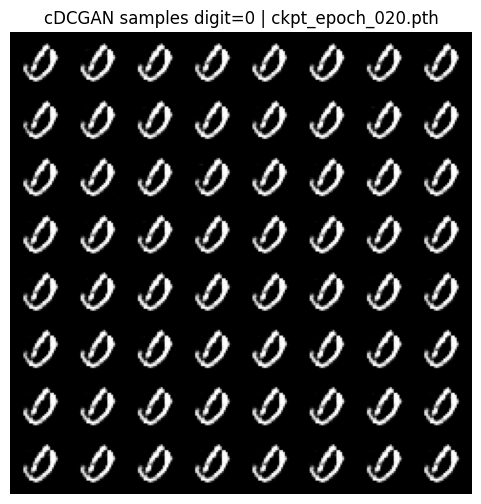

In [ ]:
paths = get_experiment_paths("03_cdcgan")

ckpt_path = latest_ckpt(paths.models_dir)
ckpt = torch.load(ckpt_path, map_location=device)

z_dim = ckpt.get("z_dim", 100)
feat = ckpt.get("feat", 64)
embed_dim = ckpt.get("embed_dim", 100)
num_classes = ckpt.get("num_classes", 10)

G = CGenerator(z_dim=z_dim, num_classes=num_classes, embed_dim=embed_dim, feat=feat).to(device)
D = CDiscriminator(num_classes=num_classes, feat=feat).to(device)

G.load_state_dict(ckpt["G"])
D.load_state_dict(ckpt["D"])

G.eval()

digit = 0  # sample this digit
with torch.no_grad():
    z = torch.randn(64, z_dim, 1, 1, device=device)
    y = torch.full((64,), digit, device=device, dtype=torch.long)
    samples = G(z, y)

show_grid(samples, title=f"cDCGAN samples digit={digit} | {ckpt_path.name}")